## Imports 

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns
from sklearn.model_selection import TimeSeriesSplit

ruta_datos = Path("..") / "data" / "processed" / "datos_preprocess.csv"
df = pd.read_csv(ruta_datos, parse_dates=["DIA"])

Como tengo que guardar las columnas borradas así el pipeline toma las correctas, creo el json y una función para registrar.

In [2]:
import json

(Path("..") / "data" / "processed" / "columnas_borradas.json").unlink(missing_ok=True)

ruta_columnas = Path("..") / "data" / "processed" / "tratamiento_columnas.json"
# arranca vacío en cada corrida: refleja solo los pasos que corrió esta notebook
registro_columnas = {}  
ruta_columnas.write_text(json.dumps(registro_columnas), encoding="utf-8")

def registrar_borradas(paso, columnas):
    """Guarda en el JSON las columnas borradas en un paso (pisa el paso si ya existía).
    Si alguna columna borrada tenía tratamientos registrados, se los quita."""
    registro_columnas[paso] = sorted(columnas)
    tratamientos = registro_columnas.get("tratamientos", {})
    for col in columnas:
        tratamientos.pop(col, None)
    ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"{paso}: {len(columnas)} columnas registradas en {ruta_columnas.name}")

def registrar_tratamiento(columnas, tratamiento):
    """Agrega el tratamiento a la lista de cada columna (clave 'tratamientos': {columna: [tratamientos en orden]}).
    Si la columna ya tiene ese tratamiento no lo repite (por si se vuelve a correr la celda)."""
    tratamientos = registro_columnas.setdefault("tratamientos", {})
    for col in columnas:
        lista = tratamientos.setdefault(col, [])
        if tratamiento not in lista:
            lista.append(tratamiento)
    ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"{tratamiento}: {len(columnas)} columnas registradas en {ruta_columnas.name}")

## Valores Nulos

In [3]:
def matriz_nulidad(datos, umbral=None, titulo="Matriz de nulidad por fecha", col_fecha="DIA"):
    """Grafica los nulos por día (filas, en orden cronológico) y por columna (de más a menos nulos).

    Negro = nulo. Si se pasa `umbral` (en %), marca las columnas que lo superan.
    Las líneas azules indican desde qué fecha aporta cada archivo (después del recorte de jul-ago).
    """
    n_nulos = datos.isna().sum()
    cols_con_nulos = n_nulos[n_nulos > 0].sort_values(ascending=False, kind="stable").index
    if len(cols_con_nulos) == 0:
        print("No hay columnas con nulos.")
        return

    matriz = datos.sort_values(col_fecha).set_index(col_fecha)[cols_con_nulos].isna()
    fechas = matriz.index

    fig, ax = plt.subplots(figsize=(14, 9))
    ax.imshow(matriz.to_numpy(), aspect="auto", cmap="Greys", interpolation="nearest")

    # Eje Y: fechas cada trimestre
    marcas = np.where(fechas.is_month_start & fechas.month.isin([1, 4, 7, 10]))[0]
    ax.set_yticks(marcas)
    ax.set_yticklabels(fechas[marcas].strftime("%Y-%m"))
    ax.set_ylabel("Día (orden cronológico)")

    # Eje X: demasiadas columnas para rotularlas una por una
    ax.set_xticks([])
    ax.set_xlabel(f"{len(cols_con_nulos)} columnas con nulos, de más a menos nulos")

    # Columnas que superan el umbral (quedan a la izquierda por el orden)
    if umbral is not None:
        pct = n_nulos[cols_con_nulos] / len(datos) * 100
        n_sobre_umbral = (pct > umbral).sum()
        if n_sobre_umbral > 0:
            ax.axvline(n_sobre_umbral - 0.5, color="red", linewidth=1.5)
            ax.text(n_sobre_umbral, 5, f" ← > {umbral} % de nulos ({n_sobre_umbral})",
                    color="red", va="top", fontsize=9)

    # Desde dónde aporta cada archivo
    for fecha, archivo in [("2021-09-01", "2021_2023"), ("2022-09-01", "2022_2023")]:
        if pd.Timestamp(fecha) in fechas:
            y = fechas.get_loc(pd.Timestamp(fecha))
            ax.axhline(y, color="tab:blue", linestyle="--", linewidth=1)
            ax.text(len(cols_con_nulos) - 1, y, f"entra {archivo} ({fecha})",
                    color="tab:blue", ha="right", va="bottom", fontsize=9)

    ax.set_title(titulo)
    plt.tight_layout()
    plt.show()

En primer lugar vamos a ver la cantidad de nulos por %, y ver cuantos son y cuanto efecto va a tener borrarlos. Como valor inicial de muestra tomamos 45% (más tarde lo cambiamos a 36, justifico más abajo) como el umbral de nulos máximo para borrarlo.

In [4]:
UMBRAL_NULOS = 36
protegidas = ["DIA", "target", "Consolidado EE | Frio (Kw)"]

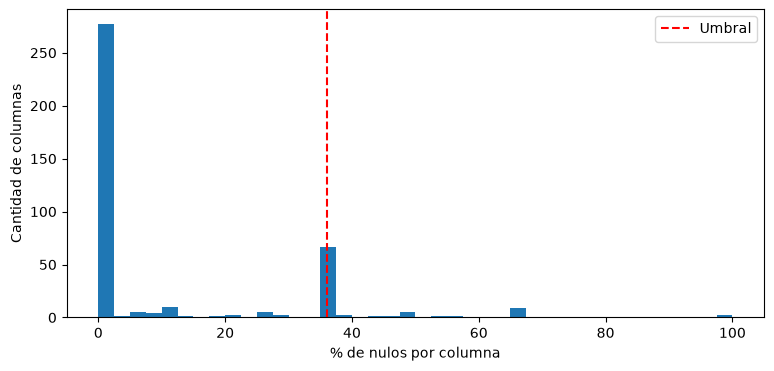

In [5]:
pct_nulos = df.isna().mean().mul(100).sort_values(ascending=False)

# Cuántas columnas caen en cada rango de % de nulos
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(pct_nulos, bins=40)
ax.set_xlabel("% de nulos por columna")
ax.set_ylabel("Cantidad de columnas")

# Umbral Nulos
ax.axvline(UMBRAL_NULOS, color="red", linestyle="--", label="Umbral")
ax.legend()
plt.show()

Hay un pico de nulos cerca del 40. Los voy a buscar y voy a ver que está pasando.

In [6]:
n_nulos = df.isna().sum()
en_rango = n_nulos[(pct_nulos > 25) & (pct_nulos <= 45)]
conteo = en_rango.value_counts()
display(conteo.head(5).rename_axis("cantidad de nulos").to_frame("columnas"))

n_pico = conteo.index[0]
cols_pico = en_rango[en_rango == n_pico].index
print(f"Pico: {n_pico} nulos ({n_pico / len(df) * 100:.2f} %) en {len(cols_pico)} de {len(en_rango)} columnas del rango 25-45 %")

nulos_pico = df[cols_pico].isna()
detalle = pd.DataFrame({
    "primer dato": df.loc[nulos_pico.eq(False).idxmax(), "DIA"].to_numpy(),
    "último nulo": df.loc[nulos_pico[::-1].idxmax(), "DIA"].to_numpy(),
}, index=cols_pico)


,columnas
cantidad de nulos,
427,67
326,3
311,2
351,2
465,1


Pico: 427 nulos (35.20 %) en 67 de 77 columnas del rango 25-45 %


In [7]:
for (primero, ultimo), grupo in detalle.groupby(["primer dato", "último nulo"]):
    print(f"\nPrimer dato: {primero.date()} | último nulo: {ultimo.date()} -> {len(grupo)} columnas")
    for col in sorted(grupo.index):
        print(f"  - {col}")


Primer dato: 2021-09-01 | último nulo: 2021-08-31 -> 67 columnas
  - Consolidado Agua | Agua CO2
  - Consolidado Agua | Agua Calderas
  - Consolidado Agua | Agua Cond Evaporativos
  - Consolidado Agua | Agua Efluentes
  - Consolidado Agua | Agua Lavadora L3
  - Consolidado Agua | Agua Paste L3
  - Consolidado GasVapor | Medicion Gas Planta (M3)
  - Consolidado GasVapor | Tot Vap Lav L3 / Hora
  - Consolidado GasVapor | Tot Vap Paste L3 / Hora
  - Consolidado GasVapor | Vapor_L5 (KG)
  - Consolidado KPI | Agua Lavadora L3 / Hl
  - Consolidado KPI | Agua Paste L3 / Hl
  - Consolidado KPI | Meta Agua Bodega
  - Consolidado KPI | Meta Agua Cocina
  - Consolidado KPI | Meta Agua Elab
  - Consolidado KPI | Meta Agua Envas
  - Consolidado KPI | Meta Agua Linea 2
  - Consolidado KPI | Meta Agua Linea 3
  - Consolidado KPI | Meta Agua Linea 4
  - Consolidado KPI | Meta Agua Linea 5
  - Consolidado KPI | Meta Agua Planta
  - Consolidado KPI | Meta Agua Planta de Agua
  - Consolidado KPI | Meta 

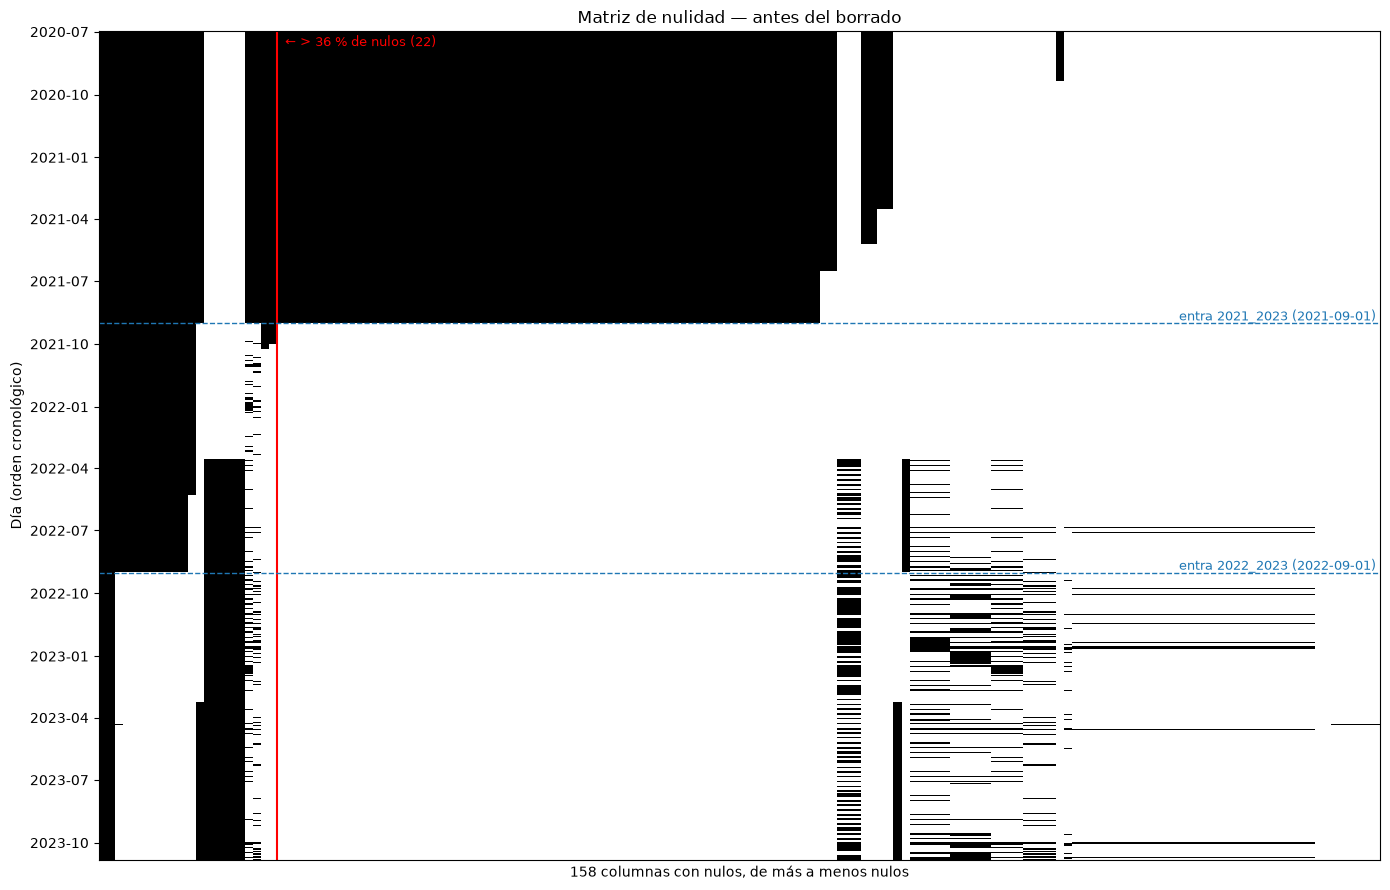

In [8]:
matriz_nulidad(df, umbral=UMBRAL_NULOS, titulo="Matriz de nulidad — antes del borrado")

### Borrado de nulos por umbral y nueva matriz

Viendo la matriz de nulidad, hay un año entero de datos faltantes. Voy a borrar los otros primero y ver cual es el problema.

In [9]:
a_borrar = pct_nulos[(pct_nulos > UMBRAL_NULOS) & ~pct_nulos.index.isin(protegidas)].index
df_nulos = df.drop(columns=a_borrar)

print(f"Columnas borradas (> {UMBRAL_NULOS} % de nulos): {len(a_borrar)}")
print(f"Columnas: {df.shape[1]} -> {df_nulos.shape[1]}")

# Guardo en el .json
registrar_borradas(f"nulos_mayor_{UMBRAL_NULOS}", a_borrar)

Columnas borradas (> 36 % de nulos): 22
Columnas: 397 -> 375
nulos_mayor_36: 22 columnas registradas en tratamiento_columnas.json


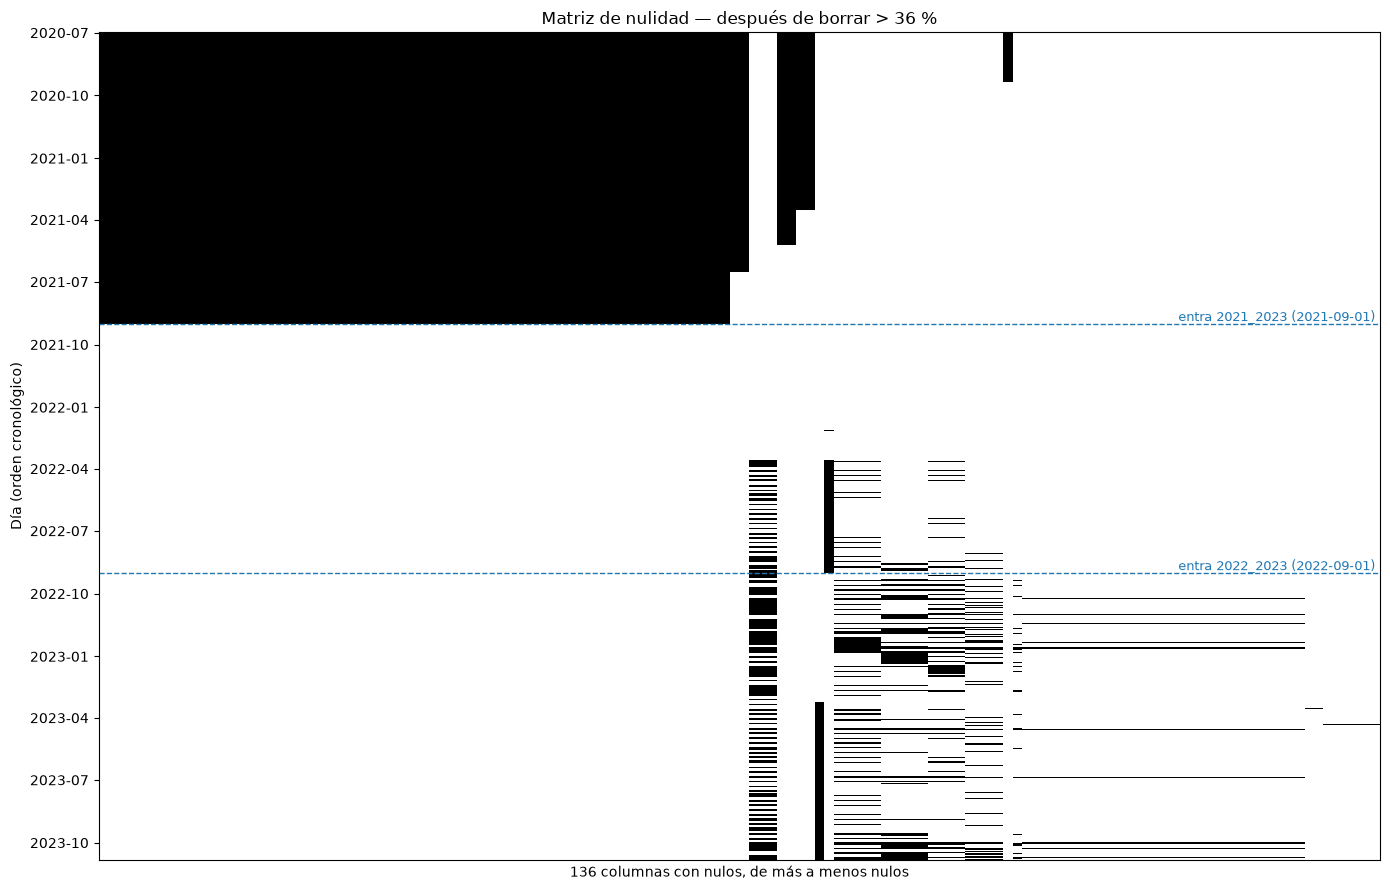

In [10]:
matriz_nulidad(df_nulos, umbral=UMBRAL_NULOS, titulo=f"Matriz de nulidad — después de borrar > {UMBRAL_NULOS} %")

### Metas
Ya teníamos la sospecha que metas no estaban en los datos mas viejos, lo confirmamos:

In [11]:
cols_meta = [c for c in df.columns if c.split(" | ", 1)[-1].strip().lower().startswith("meta")]
pct_meta = df[cols_meta].isna().mean().mul(100).sort_values(ascending=False)

borradas_meta = [c for c in cols_meta if c in a_borrar]
print(f"Columnas de metas: {len(cols_meta)} | borradas por > {UMBRAL_NULOS} % de nulos: {len(borradas_meta)} "
      f"| quedan en df_nulos: {len(cols_meta) - len(borradas_meta)}\n")

for col, pct in pct_meta.items():
    estado = "  (BORRADA)" if col in a_borrar else ""
    print(f"{pct:6.2f} %  {col}{estado}")


Columnas de metas: 51 | borradas por > 36 % de nulos: 0 | quedan en df_nulos: 51

 35.20 %  Consolidado KPI | Meta EE Planta
 35.20 %  Consolidado KPI | Meta Agua Planta
 35.20 %  Consolidado KPI | Meta ET Planta
 35.20 %  Consolidado KPI | Meta Aire Planta
 35.20 %  Consolidado KPI | Meta Agua Elab
 35.20 %  Consolidado KPI | Meta Agua Bodega
 35.20 %  Consolidado KPI | Meta Agua Cocina
 35.20 %  Consolidado KPI | Meta Agua Envas
 35.20 %  Consolidado KPI | Meta Agua Linea 2
 35.20 %  Consolidado KPI | Meta Agua Linea 3
 35.20 %  Consolidado KPI | Meta Agua Linea 4
 35.20 %  Consolidado KPI | Meta Agua Linea 5
 35.20 %  Consolidado KPI | Meta Agua Servicios
 35.20 %  Consolidado KPI | Meta Agua Planta de Agua
 35.20 %  Consolidado KPI | Meta Produccion Agua
 35.20 %  Consolidado KPI | Meta EE Elaboracion
 35.20 %  Consolidado KPI | Meta EE Bodega
 35.20 %  Consolidado KPI | Meta EE Cocina
 35.20 %  Consolidado KPI | Meta EE Envasado
 35.20 %  Consolidado KPI | Meta EE Linea 2
 35.20 %

Esto seguramente ocurre por que en años pasados, no se tomaban metas de consumo. Como más abajo en feature engineering habla de eficiencia energética, seguramente sea importante. Quiero ver primero como es la estructura de meta vs consumo real en los años que si existe.

In [12]:
def ver_dias(datos, columnas, desde, dias=10, col_fecha="DIA"):
    """Muestra `dias` días seguidos desde `desde` para las `columnas` pedidas.
    Días como columnas y variables como filas. Avisa si alguna columna no está en el df."""
    faltan = [c for c in columnas if c not in datos.columns]
    if faltan:
        print("No están en el df:", faltan)
    cols = [c for c in columnas if c in datos.columns]

    inicio = pd.Timestamp(desde)
    fin = inicio + pd.Timedelta(days=dias - 1)
    ventana = datos.loc[datos[col_fecha].between(inicio, fin), [col_fecha, *cols]].set_index(col_fecha)
    ventana.index = ventana.index.strftime("%d/%m/%y")
    return ventana.T.round(3)

In [13]:
desde = "2022-02-24"

display(ver_dias(df_nulos, ["Consolidado KPI | Meta EE Planta",
                            "Consolidado KPI | EE Planta / Hl",
                            "Consolidado EE | Planta (Kw)"], desde))

DIA,24/02/22,25/02/22,26/02/22,27/02/22,28/02/22,01/03/22,02/03/22,03/03/22,04/03/22,05/03/22
Consolidado KPI | Meta EE Planta,6.500,6.500,6.50,6.500,6.500,6.500,6.500,6.500,6.300,6.350
Consolidado KPI | EE Planta / Hl,7.992,8.978,5.95,7.155,5.733,5.782,5.778,8.112,6.111,6.876
Consolidado EE | Planta (Kw),58005.580,62806.170,67257.80,63439.130,53616.450,69975.380,69911.330,61830.170,68704.870,54752.480


Metas está siempre en Hl. Lo que voy a hacer más tarde en feature engineering es crear la eficiencia energética consumo/meta; en el caso que sea perfecto significa que es 1. 
Por ahora, para poder seguir con la limpieza, voy a imputarlo con 1; **pero para el pipeline cuando tenga mi división test/train, voy a imputarlo con la media de la eficiencia**.

Columnas de metas: 51 | valores imputados con 1: 21777
Días sin meta: 427 (2020-07-01 -> 2021-08-31)


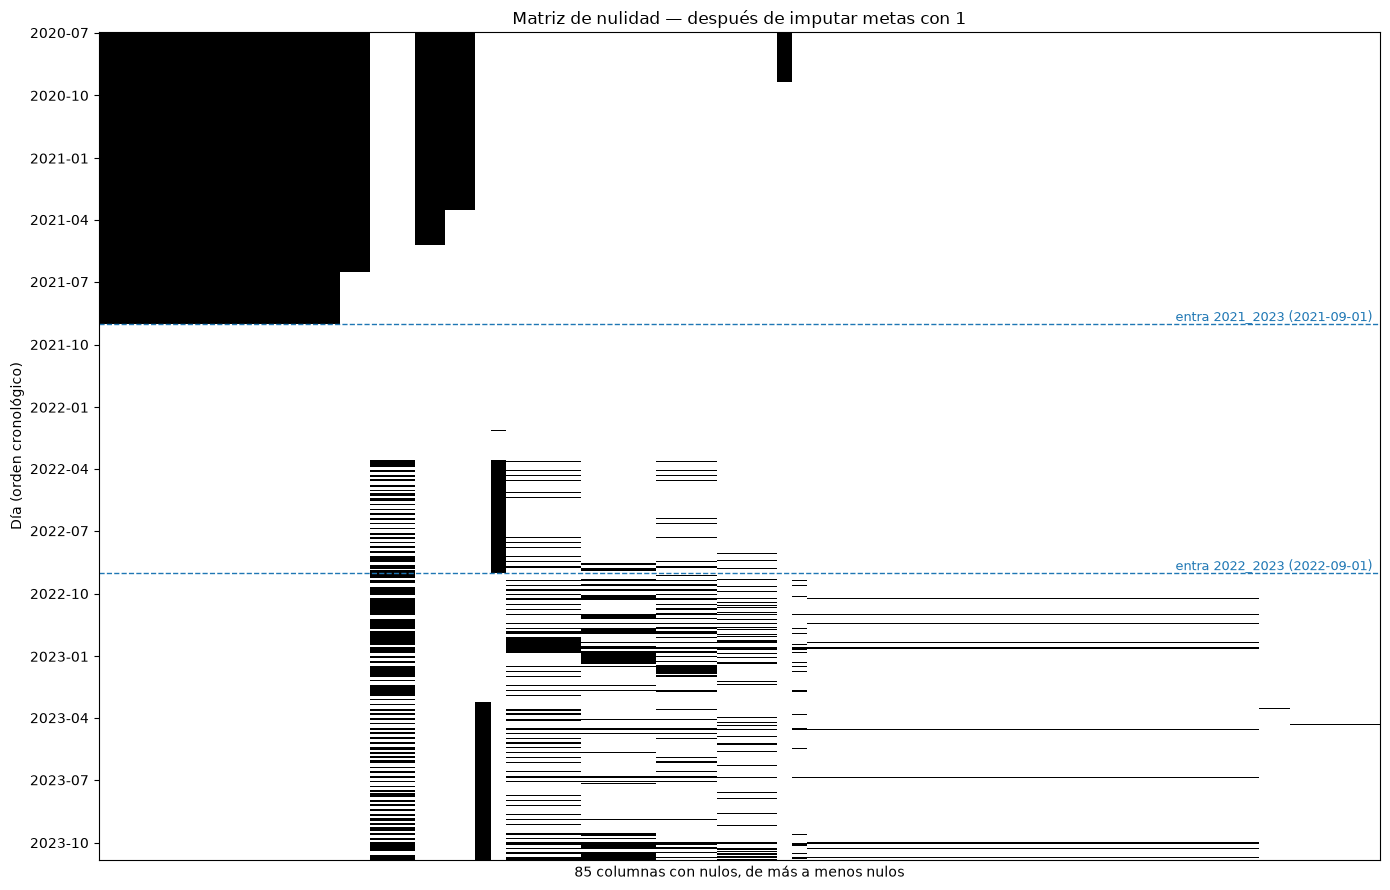

media_train_si_no_hay_meta: 51 columnas registradas en tratamiento_columnas.json


In [14]:
metas = [c for c in df_nulos.columns if c.split(" | ", 1)[-1].strip().lower().startswith("meta")]

df_metas = df_nulos.copy()

# Indicador: días sin ninguna meta (antes de rellenar, para no perder cuáles faltaban)
df_metas["no_hay_meta"] = df_metas[metas].isna().all(axis=1).astype(int)

# Relleno provisorio con 1 (se reemplaza por la media de train después del split)
n_imputados = df_metas[metas].isna().sum().sum()
df_metas[metas] = df_metas[metas].fillna(1)

sin_meta = df_metas.loc[df_metas["no_hay_meta"] == 1, "DIA"]
print(f"Columnas de metas: {len(metas)} | valores imputados con 1: {n_imputados}")
print(f"Días sin meta: {len(sin_meta)} ({sin_meta.min().date()} -> {sin_meta.max().date()})")

matriz_nulidad(df_metas, titulo="Matriz de nulidad — después de imputar metas con 1")
registrar_tratamiento(metas, "media_train_si_no_hay_meta")

In [15]:
nulos = df_metas.isna()
cols_nulos = nulos.sum()[lambda s: s > 0].sort_values(ascending=False, kind="stable").index
nulos = nulos[cols_nulos]
fechas = df_metas["DIA"]

tabla_nulos = pd.DataFrame({
    "n nulos": nulos.sum(),
    "% nulos": nulos.mean().mul(100).round(2),
    "tramos": (nulos & ~nulos.shift(fill_value=False)).sum(),   # bloques seguidos de nulos
})

print(f"Columnas con nulos: {len(tabla_nulos)} de {df_metas.shape[1]}")
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(tabla_nulos)

Columnas con nulos: 85 de 376


,n nulos,% nulos,tramos
Consolidado KPI | Agua Lavadora L3 / Hl,427,35.20,1
Consolidado KPI | Agua Paste L3 / Hl,427,35.20,1
Consolidado Produccion | Hl de Mosto Copia,427,35.20,1
Consolidado Agua | Agua Paste L3,427,35.20,1
Consolidado Agua | Agua Lavadora L3,427,35.20,1
Consolidado Agua | Agua Cond Evaporativos,427,35.20,1
Consolidado Agua | Agua Calderas,427,35.20,1
Consolidado Agua | Agua Efluentes,427,35.20,1
Consolidado Agua | Agua CO2,427,35.20,1
Consolidado GasVapor | Vapor_L5 (KG),427,35.20,1


Me freno en la parte debajo de Totalizadores Glicol - Tot Traziego. Todos esos valores vienen de KPI (menos los ultimos, que son un único nulo).
Son pocos y ra el porcentaje del dataset, así que directamente los voy a imputar por por la media pero usando el vecinos anteriores (no uso vecinos nuevos por que estoy usando información futura).

In [16]:
def imputar_promedio_anteriores(datos, columnas, n=2, col_fecha="DIA", invalidar_negativos=False):
    """Rellena cada nulo con el promedio de los `n` valores válidos anteriores.

    Solo mira hacia atrás: no usa información del futuro
    y se comporta igual en train que en predict.py.
    Si hay varios nulos seguidos, todos reciben el promedio de los n válidos previos al hueco.
    Si no hay ningún valor válido antes (inicio de la serie), usa el siguiente válido.
    Si `invalidar_negativos=True`, los negativos se tratan como nulos.
    """
    df = datos.sort_values(col_fecha).copy()
    if invalidar_negativos:
        df[columnas] = df[columnas].mask(df[columnas] < 0)
    for col in columnas:
        s = df[col]
        media_previa = s.dropna().rolling(n, min_periods=1).mean().reindex(s.index).ffill()
        df[col] = s.fillna(media_previa).fillna(s.bfill())
    return df

Columnas imputadas: 38 | valores imputados: 668
Nulos que quedan en esas columnas: 0
promedio_anteriores: 38 columnas registradas en tratamiento_columnas.json


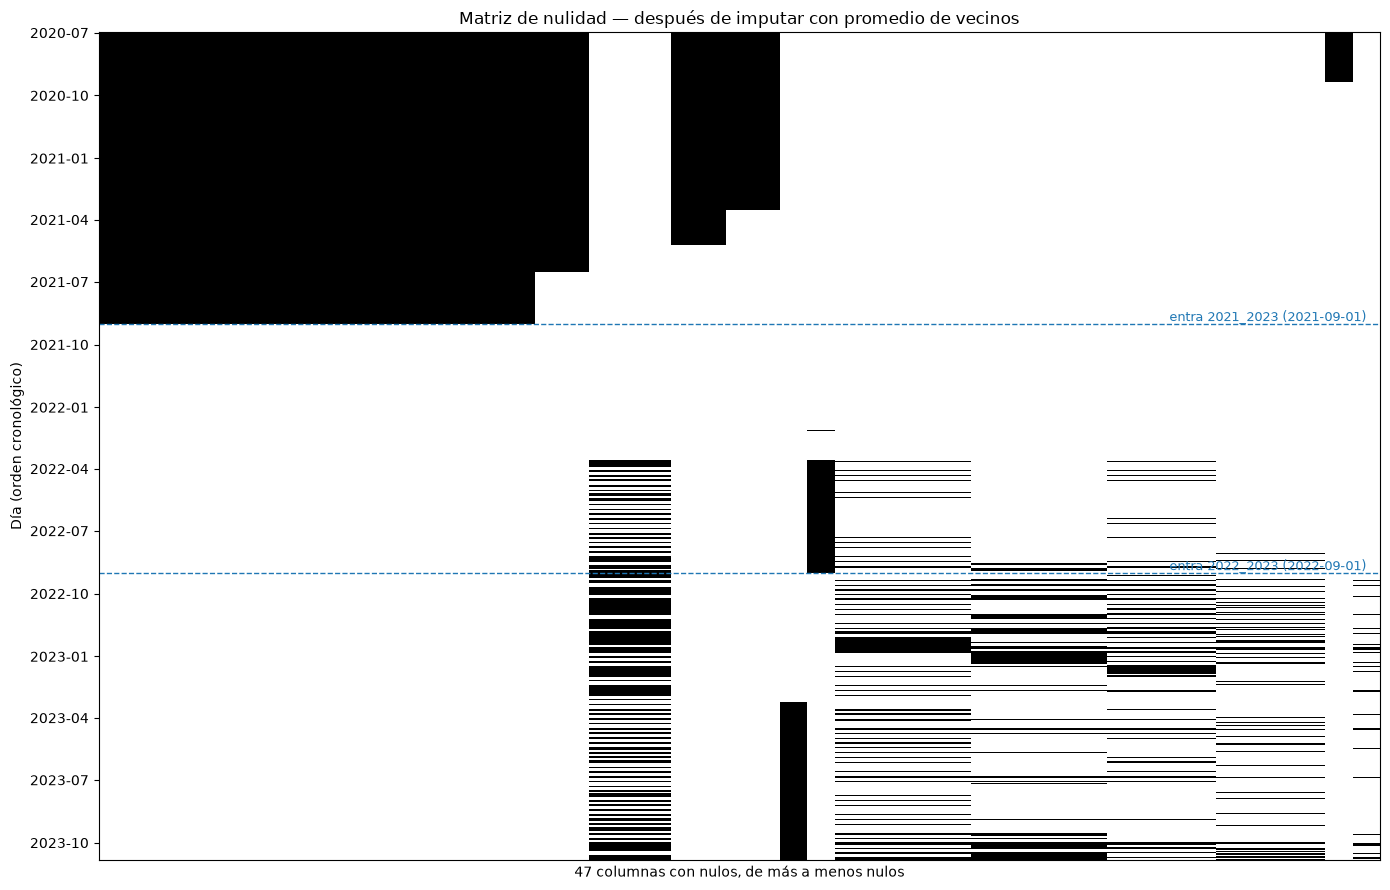

In [17]:
pos_ee = tabla_nulos.index.get_loc("Consolidado KPI | EE Planta / Hl")
cols_vecinos = list(tabla_nulos.index[pos_ee:])

df_imp = imputar_promedio_anteriores(df_metas, cols_vecinos)

print(f"Columnas imputadas: {len(cols_vecinos)} | valores imputados: {df_metas[cols_vecinos].isna().sum().sum()}")
print(f"Nulos que quedan en esas columnas: {df_imp[cols_vecinos].isna().sum().sum()}")

registrar_tratamiento(cols_vecinos, "promedio_anteriores")

matriz_nulidad(df_imp, titulo="Matriz de nulidad — después de imputar con promedio de vecinos")

Columnas con uno o dos tramos de nulos: 25

 35.20 %  (1 tramo)  Consolidado Agua | Agua CO2
 35.20 %  (1 tramo)  Consolidado Agua | Agua Efluentes
 35.20 %  (1 tramo)  Consolidado Agua | Agua Calderas
 35.20 %  (1 tramo)  Consolidado Agua | Agua Cond Evaporativos
 35.20 %  (1 tramo)  Consolidado Agua | Agua Lavadora L3
 35.20 %  (1 tramo)  Consolidado Agua | Agua Paste L3
 35.20 %  (1 tramo)  Consolidado Produccion | Hl de Mosto Copia
 35.20 %  (1 tramo)  Consolidado KPI | Agua Paste L3 / Hl
 35.20 %  (1 tramo)  Consolidado KPI | Agua Lavadora L3 / Hl
 35.20 %  (1 tramo)  Consolidado GasVapor | Medicion Gas Planta (M3)
 35.20 %  (1 tramo)  Consolidado GasVapor | Vapor_L5 (KG)
 35.20 %  (1 tramo)  Consolidado GasVapor | Tot Vap Paste L3 / Hora
 35.20 %  (1 tramo)  Consolidado GasVapor | Tot Vap Lav L3 / Hora
 35.20 %  (1 tramo)  Totalizadores Glicol | Tot A40/240/50/60/Centec/Filtro
 35.20 %  (1 tramo)  Totalizadores Gas y Vapor | Vapor_L5 (KG)
 35.20 %  (1 tramo)  Totalizadores Glicol

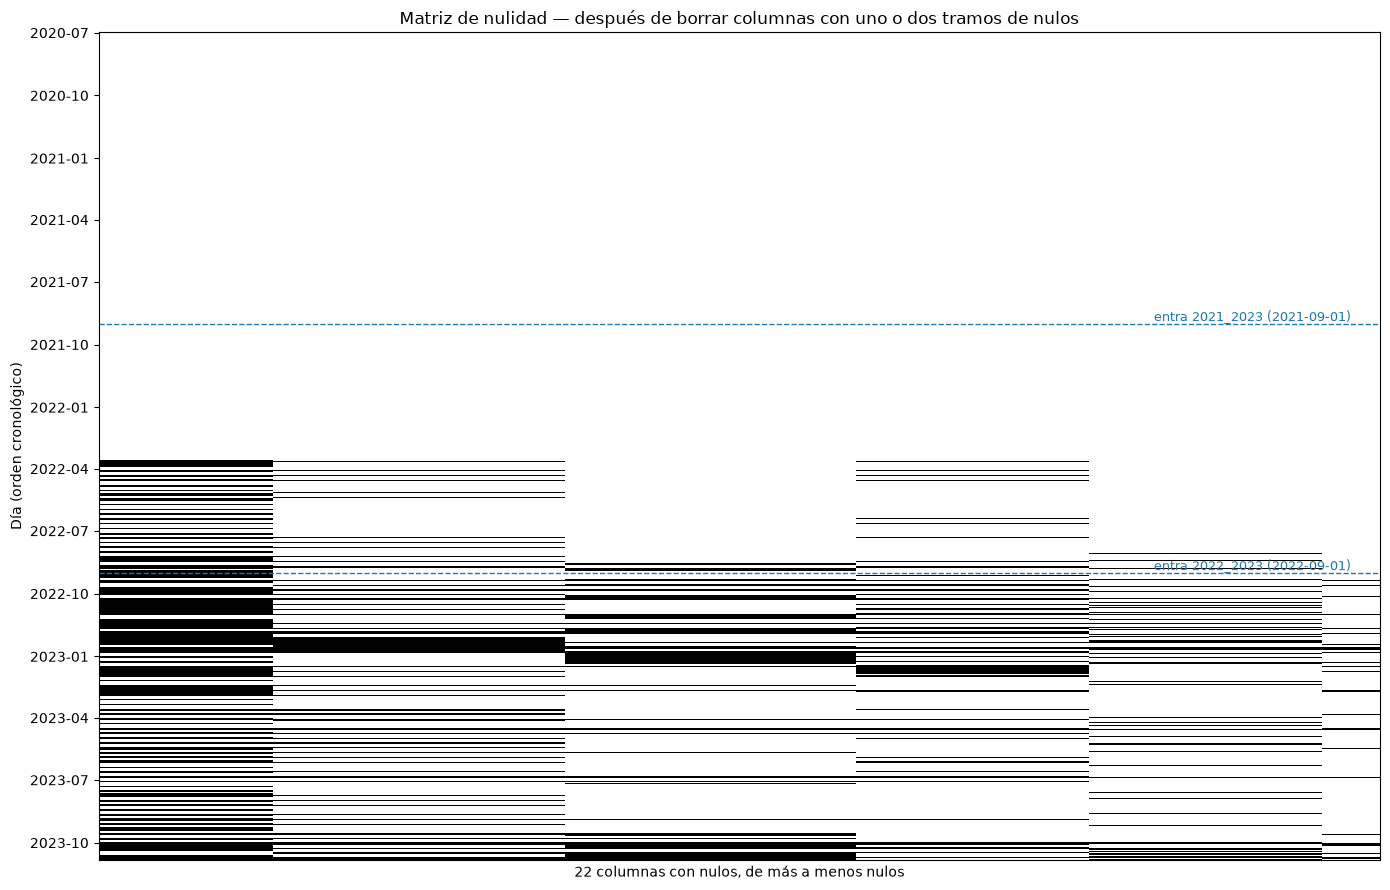

In [18]:
nulos_imp = df_imp.isna()
tramos = (nulos_imp & ~nulos_imp.shift(fill_value=False)).sum()
pocos_tramos = tramos[tramos.between(1, 2) & ~tramos.index.isin(protegidas)].index

pct_pocos = nulos_imp[pocos_tramos].mean().mul(100).sort_values(ascending=False)
print(f"Columnas con uno o dos tramos de nulos: {len(pocos_tramos)}\n")
for col, pct in pct_pocos.items():
    print(f"{pct:6.2f} %  ({tramos[col]} tramo{'s' if tramos[col] > 1 else ''})  {col}")

df_tramo = df_imp.drop(columns=pocos_tramos)
print(f"\nColumnas: {df_imp.shape[1]} -> {df_tramo.shape[1]}")

registrar_borradas("nulos_uno_o_dos_tramos", pocos_tramos)

matriz_nulidad(df_tramo, titulo="Matriz de nulidad — después de borrar columnas con uno o dos tramos de nulos")

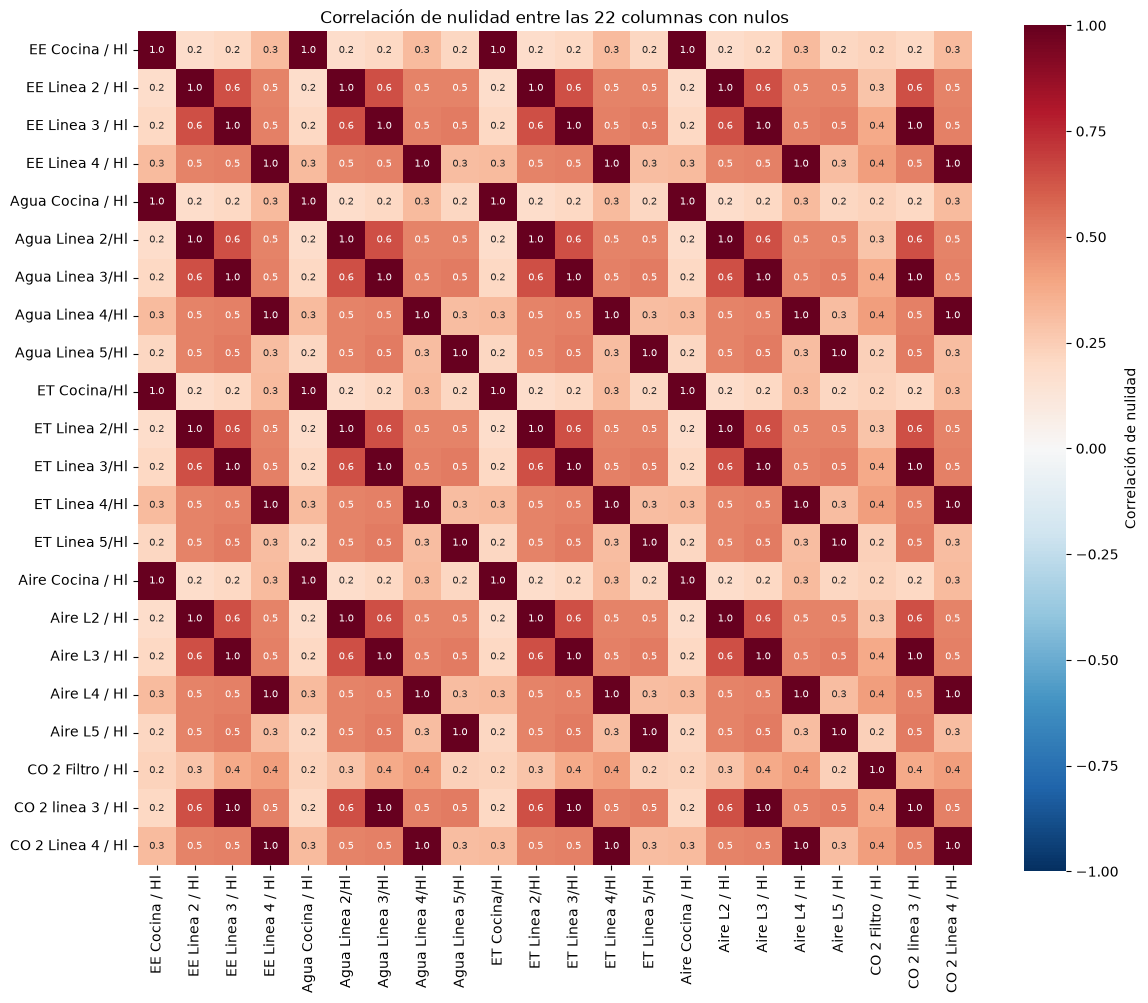

In [19]:
cols_restantes = df_tramo.columns[df_tramo.isna().any()]
corr_nul = df_tramo[cols_restantes].isna().corr()
corr_nul.index = corr_nul.columns = [c.split(" | ", 1)[-1] for c in cols_restantes]

plt.figure(figsize=(12, 10))
sns.heatmap(corr_nul, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".1f",
            annot_kws={"size": 7}, square=True, cbar_kws={"label": "Correlación de nulidad"})
plt.title(f"Correlación de nulidad entre las {len(corr_nul)} columnas con nulos")
plt.tight_layout()
plt.show()

Acá claramente hay una relación entre las lineas de producción. La voy a ordenar por area y ver:

Cocina: EE Cocina / Hl, Agua Cocina / Hl, ET Cocina/Hl, Aire Cocina / Hl
Línea 2: EE Linea 2 / Hl, Agua Linea 2/Hl, ET Linea 2/Hl, Aire L2 / Hl
Línea 3: EE Linea 3 / Hl, Agua Linea 3/Hl, ET Linea 3/Hl, Aire L3 / Hl, CO 2 linea 3 / Hl
Línea 4: EE Linea 4 / Hl, Agua Linea 4/Hl, ET Linea 4/Hl, Aire L4 / Hl, CO 2 Linea 4 / Hl
Línea 5: Agua Linea 5/Hl, ET Linea 5/Hl, Aire L5 / Hl
Filtro: CO 2 Filtro / Hl


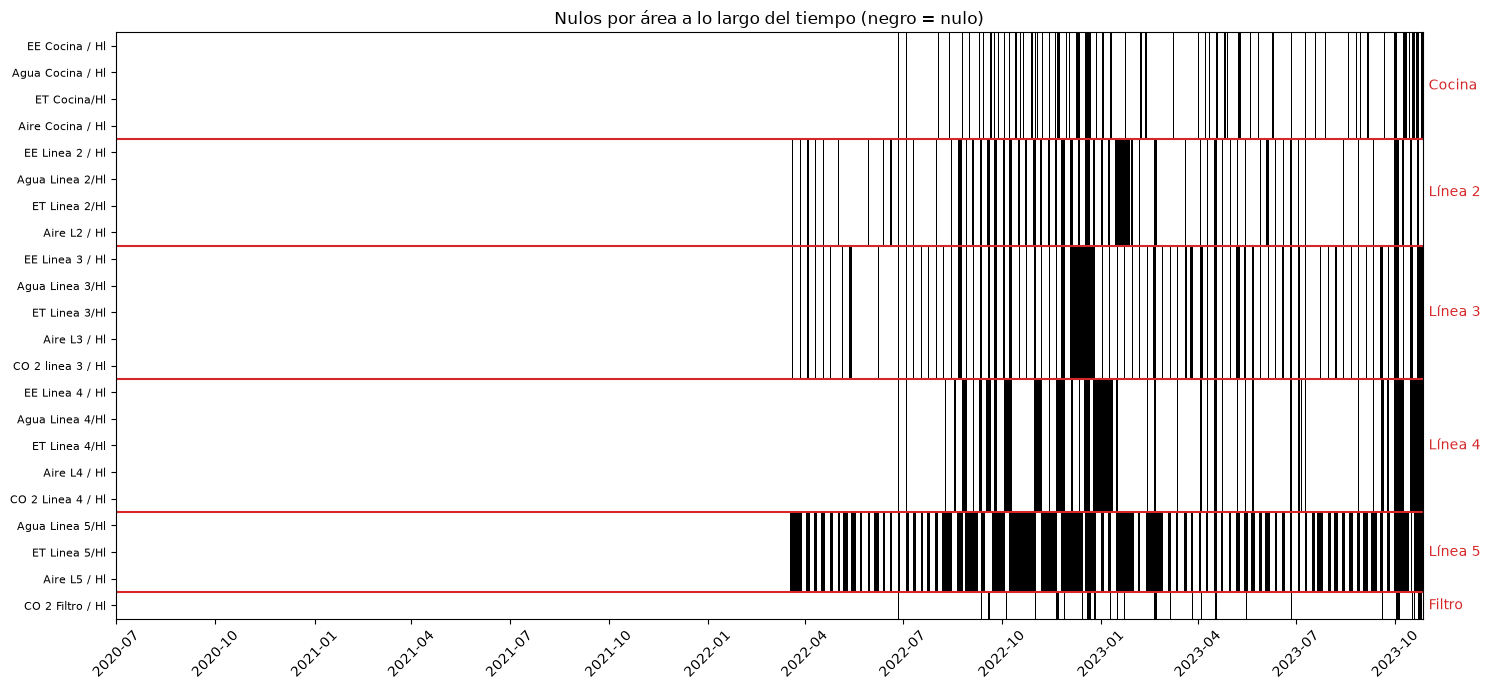

In [20]:
import re

def linea_de(col):
    """Devuelve el área (Cocina, Línea 2-5, Filtro) según el nombre de la columna."""
    nombre = col.split(" | ", 1)[-1]
    patrones = [("Cocina", r"Cocina"), ("Filtro", r"Filtro")] + \
               [(f"Línea {n}", rf"L(?:inea)?\s*{n}\b") for n in [2, 3, 4, 5]]
    for area, patron in patrones:
        if re.search(patron, nombre, flags=re.IGNORECASE):
            return area
    return "Otra"

orden = ["Cocina", "Línea 2", "Línea 3", "Línea 4", "Línea 5", "Filtro", "Otra"]
cols_restantes = df_tramo.columns[df_tramo.isna().any()]
area = pd.Series({c: linea_de(c) for c in cols_restantes})
area = area.sort_values(key=lambda s: s.map(orden.index), kind="stable")

# Listado por área
for nombre_area, cols in area.groupby(area, sort=False):
    print(f"{nombre_area}: {', '.join(c.split(' | ', 1)[-1] for c in cols.index)}")

# Matriz: filas = columnas agrupadas por área, columnas = días
matriz = df_tramo.sort_values("DIA").set_index("DIA")[area.index].isna().T
fechas = matriz.columns

fig, ax = plt.subplots(figsize=(15, 7))
ax.imshow(matriz.to_numpy(), aspect="auto", cmap="Greys", interpolation="nearest")  # negro = nulo

ax.set_yticks(range(len(area)))
ax.set_yticklabels([c.split(" | ", 1)[-1] for c in area.index], fontsize=8)

marcas = np.where(fechas.is_month_start & fechas.month.isin([1, 4, 7, 10]))[0]
ax.set_xticks(marcas)
ax.set_xticklabels(fechas[marcas].strftime("%Y-%m"), rotation=45)

# Separadores y nombre de cada área a la derecha
limites = area.groupby(area, sort=False).size().cumsum()
inicio = 0
for nombre_area, fin in limites.items():
    if fin < len(area):
        ax.axhline(fin - 0.5, color="tab:red", linewidth=1.5)
    ax.text(len(fechas) + 5, (inicio + fin - 1) / 2, nombre_area, va="center", fontsize=10,
            color="tab:red", clip_on=False)
    inicio = fin

ax.set_title("Nulos por área a lo largo del tiempo (negro = nulo)")
plt.tight_layout()
plt.show()

Ahí están claras las relaciones entre líneas y sus nulos.

Lo que voy a hacer es codificar cuando una línea estuvo parada, y despues voy a imputar por el promedio de los vecinos, como hice para los otros nulos. 

In [21]:
df_lineas = df_tramo.copy()

# Indicador por área: 1 si ese día faltaban los datos del área (antes de imputar)
for nombre_area, cols in area.groupby(area, sort=False):
    df_lineas[f"nulo_{nombre_area}"] = df_lineas[cols.index].isna().any(axis=1).astype(int)

# Largo promedio de los huecos por columna (justifica imputar por vecinos)
nulos_area = df_lineas[area.index].isna()
tramos_area = (nulos_area & ~nulos_area.shift(fill_value=False)).sum()
largo = (nulos_area.sum() / tramos_area).groupby(area).mean().reindex(orden).dropna()
display(largo.round(1))

# Imputación columna por columna con sus vecinos en el tiempo
df_lineas = imputar_promedio_anteriores(df_lineas, list(area.index))

registrar_tratamiento(list(area.index), "promedio_anteriores")

matriz_nulidad(df_lineas, titulo="Matriz de nulidad — después de imputar por línea")

Cocina     1.4
Línea 2    1.9
Línea 3    1.8
Línea 4    3.2
Línea 5    4.9
Filtro     1.5
dtype: float64

promedio_anteriores: 22 columnas registradas en tratamiento_columnas.json
No hay columnas con nulos.


## Columnas con valores negativos

La verdad es que tendríamos que haber visto esto antes, pero lo vengo aplazando. Hago un df con los valores nulos: 

In [22]:
def negativos_por_columna(datos, excluir=("DIA",), col_fecha="DIA"):
    """Tabla de columnas con valores negativos: cuántos, el mínimo y entre qué fechas aparecen."""
    x = datos.drop(columns=list(excluir)).select_dtypes("number")
    neg = x < 0
    cols = neg.columns[neg.any()]
    if len(cols) == 0:
        print("No hay valores negativos.")
        return pd.DataFrame()

    fechas = datos[col_fecha]
    tabla = pd.DataFrame({
        "n negativos": neg[cols].sum(),
        "% negativos": neg[cols].mean().mul(100).round(2),
        "mínimo": x[cols].min(),
    })
    return tabla.sort_values("n negativos", ascending=False)


def pasar_a_positivo(datos, columnas):
    """Devuelve una copia con las `columnas` en valor absoluto."""
    df = datos.copy()
    df[columnas] = df[columnas].abs()
    return df


In [23]:
tabla_neg = negativos_por_columna(df_lineas)
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(tabla_neg)

,n negativos,% negativos,mínimo
DS_cos,694,57.21,-9.009689e-01
MES_cos,670,55.23,-1.000000e+00
EST_cos,667,54.99,-1.000000e+00
MES_sin,547,45.09,-1.000000e+00
DS_sin,520,42.87,-9.749279e-01
EST_sin,330,27.21,-1.000000e+00
Consolidado EE | Resto Serv (Kw),40,3.30,-5.535738e+06
Consolidado KPI | EE Resto Serv / Hl,39,3.22,-7.074199e+02
Consolidado Aire | Aire Servicios (M3),25,2.06,-1.489944e+05
Consolidado KPI | Aire Servicios / Hl,24,1.98,-6.528977e+01


Los primeros son los dias/meses/etc codificados, los dejo como están. Mas abajo parecen ser todos errores simples del medidor. 

In [24]:
# Columnas que se dejan como están: codificación cíclica (negativos legítimos) y los Restos (se analizan aparte)
es_ciclica = tabla_neg.index.str.endswith(("_sin", "_cos"))
es_resto = tabla_neg.index.str.contains("Resto", case=False)

cols_neg_imputar = list(tabla_neg.index[~es_ciclica & ~es_resto])
print(f"Columnas a imputar: {len(cols_neg_imputar)} | valores negativos: {(df_lineas[cols_neg_imputar] < 0).sum().sum()}")

df_neg = imputar_promedio_anteriores(df_lineas, cols_neg_imputar, invalidar_negativos=True)
registrar_tratamiento(cols_neg_imputar, "promedio_anteriores_sin_negativos")

tabla_neg = negativos_por_columna(df_neg)
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(tabla_neg)

Columnas a imputar: 27 | valores negativos: 138
promedio_anteriores_sin_negativos: 27 columnas registradas en tratamiento_columnas.json


,n negativos,% negativos,mínimo
DS_cos,694,57.21,-9.009689e-01
MES_cos,670,55.23,-1.000000e+00
EST_cos,667,54.99,-1.000000e+00
MES_sin,547,45.09,-1.000000e+00
DS_sin,520,42.87,-9.749279e-01
EST_sin,330,27.21,-1.000000e+00
Consolidado EE | Resto Serv (Kw),40,3.30,-5.535738e+06
Consolidado KPI | EE Resto Serv / Hl,39,3.22,-7.074199e+02
Consolidado EE | Restos Planta (Kw),18,1.48,-4.492792e+06
Consolidado KPI | EE Resto Planta / Hl,15,1.24,-5.876004e+02


Ahora que (a propósito) imputé los valores que seguramente eran simples errores, me quedan las 4 columnas con Resto que me hacen ruido, por que no las encontraba en la explicación del dataset.

Nobleza obliga, Claude encontró la relación que tienen con el resto de las columnasa; son restas de la producción total - las diferentes areas, para revisar los medidores. Como estas son combinaciones de las otras columnas, lo que voy a hacer es borrarlas (me imagino que hubieran saltado en los filtros de correlación más adelante). 

In [25]:
cols_resto = [c for c in df_neg.columns if "resto" in c.lower()]
print(f"Columnas Resto a borrar: {len(cols_resto)}")
for c in cols_resto:
    print(f"  - {c}")

df_sin_resto = df_neg.drop(columns=cols_resto)
print(f"Columnas: {df_neg.shape[1]} -> {df_sin_resto.shape[1]}")

registrar_borradas("restos_redundantes", cols_resto)

Columnas Resto a borrar: 6
  - Consolidado KPI | EE Resto Serv / Hl
  - Consolidado KPI | EE Resto Planta / Hl
  - Consolidado EE | Resto Serv (Kw)
  - Consolidado EE | Restos Planta (Kw)
  - Consolidado KPI | Meta EE Resto Serv
  - Consolidado KPI | Meta EE Resto Planta
Columnas: 357 -> 351
restos_redundantes: 6 columnas registradas en tratamiento_columnas.json


## Columnas Identicas y con todos 0s

Primero veo cuales tienen 0 en todos sus valores.

In [26]:
x_num = df_sin_resto.drop(columns="DIA")
cols_cero = list(x_num.columns[(x_num == 0).all()])
print(f"Columnas con todos sus valores en 0: {len(cols_cero)} de {x_num.shape[1]}")

Columnas con todos sus valores en 0: 18 de 350


In [27]:
df_sin_cero = df_sin_resto.drop(columns=cols_cero)
print(f"Columnas: {df_sin_resto.shape[1]} -> {df_sin_cero.shape[1]}")
registrar_borradas("columnas_en_cero", cols_cero)

Columnas: 351 -> 333
columnas_en_cero: 18 columnas registradas en tratamiento_columnas.json


Y ahora veo las columnas que son idénticas:

In [28]:
def columnas_identicas(datos, excluir=("DIA",)):
    """Agrupa las columnas que tienen exactamente los mismos valores en todas las filas.
    Devuelve una lista de grupos (cada grupo, una lista de columnas en el orden del df)."""
    x = datos.drop(columns=list(excluir))
    firma = x.T.apply(tuple, axis=1)   # todos los valores de la columna, en orden
    grupos = firma.groupby(firma, sort=False).groups
    return [list(cols) for cols in grupos.values() if len(cols) > 1]

# Las metas se excluyen: aunque haya metas con los mismos valores, cada una va con su propio KPI
metas_ident = [c for c in df_sin_cero.columns if c.split(" | ", 1)[-1].strip().lower().startswith("meta")]
grupos_ident = columnas_identicas(df_sin_cero, excluir=("DIA", *metas_ident))

In [29]:
# En cada grupo se queda una sola columna: Frio o target si están, si no la de Consolidado, si no la primera
def elegir(grupo):
    for col in grupo:
        if col in ("target", "Consolidado EE | Frio (Kw)"):
            return col
    return next((c for c in grupo if c.startswith("Consolidado")), grupo[0])

ident_borrar = [c for g in grupos_ident for c in g if c != elegir(g)]
df_sin_ident = df_sin_cero.drop(columns=ident_borrar)

print(f"Columnas: {df_sin_cero.shape[1]} -> {df_sin_ident.shape[1]}")
print(f"Quedan grupos idénticos: {len(columnas_identicas(df_sin_ident, excluir=('DIA', *metas_ident)))}")
registrar_borradas("columnas_identicas", ident_borrar)

Columnas: 333 -> 309
Quedan grupos idénticos: 0
columnas_identicas: 24 columnas registradas en tratamiento_columnas.json


## Split Test/Train

In [30]:
df_sin_ident = df_sin_ident.sort_values("DIA").reset_index(drop=True)
n_eval = round(len(df_sin_ident) * 0.15)   # días de validación y de test

# Con test_size fijo y 2 cortes, TimeSeriesSplit da:
#   corte 1: train = lo más antiguo (70 %)      | evaluación = los 15 % siguientes (validación)
#   corte 2: train = train + validación (85 %)  | evaluación = el 15 % más reciente (test)
(idx_train, idx_val), (_, idx_test) = TimeSeriesSplit(n_splits=2, test_size=n_eval).split(df_sin_ident)
es_train = df_sin_ident.index.isin(idx_train)   # máscara para calcular los límites de outliers solo con train

for nombre, idx in [("Train", idx_train), ("Validación", idx_val), ("Test", idx_test)]:
    dias = df_sin_ident.loc[idx, "DIA"]
    print(f"{nombre:<11} {len(idx):>4} días ({len(idx) / len(df_sin_ident):.1%}) | {dias.min().date()} -> {dias.max().date()}")

# Se guardan los cortes para que el modelado y el pipeline usen exactamente los mismos
registro_columnas["split"] = {nombre: str(df_sin_ident.loc[idx, "DIA"].max().date())
                              for nombre, idx in [("fin_train", idx_train), ("fin_val", idx_val)]}
ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8")

Train        849 días (70.0%) | 2020-07-01 -> 2022-10-27
Validación   182 días (15.0%) | 2022-10-28 -> 2023-04-27
Test         182 días (15.0%) | 2023-04-28 -> 2023-10-26


15640

## Outliers

Voy a usar Z-Score para obtenerlos. Mi idea es poner umbrales grandes de outliers, por que estoy trabajando con 350 columnas y no voy a poder usar LOF (mucha dimensionalidad). 

Entonces, mi plan es usar Z-Score para sacar los ruidos muy molestos, y voy a usar transformaciones más tarde para llevar todo a una escala más trabajable.

In [31]:
UMBRAL_Z = 10   #  el estándar es 3.5, agarro 10 para que salten los más altos nada más

In [32]:
def outliers_zscore(datos, umbral=3, excluir=(), filas_ref=None, col_fecha="DIA"):
    """Z-score clásico por columna: |x - media| / desvío > umbral.

    La media y el desvío se calculan solo con las filas de `filas_ref` (máscara booleana, por ejemplo train)
    y se aplican a todas las filas. Si es None, usa todas.
    Ignora columnas binarias (en las filas de referencia) y las de `excluir`.
    Devuelve: tabla por columna (ordenada por z máx) y máscara de outliers (días x columnas).
    """
    x = datos.drop(columns=[col_fecha, *excluir]).select_dtypes("number")
    ref = x if filas_ref is None else x.loc[filas_ref]
    x = x.loc[:, ref.nunique() > 2]
    ref = ref[x.columns]

    z = ((x - ref.mean()) / ref.std()).abs()
    es_out = z > umbral

    fila_max = z.idxmax()
    tabla = pd.DataFrame({
        "n outliers": es_out.sum(),
        "z máx": z.max().round(1),
        "día z máx": datos.loc[fila_max, col_fecha].dt.date.to_numpy(),
        "valor z máx": [x.at[i, c] for c, i in fila_max.items()],
        "mediana": ref.median(),
    })
    tabla = tabla[tabla["n outliers"] > 0].sort_values("z máx", ascending=False)
    return tabla, es_out


def winsorizar_marcados(datos, mascara, p_inf=0.02, p_sup=0.98, filas_ref=None,
                        frio="Consolidado EE | Frio (Kw)", col_fecha="DIA"):
    """Lleva al percentil p_inf/p_sup de su columna SOLO las celdas marcadas en `mascara`.

    Los percentiles se calculan solo con las filas de `filas_ref` (si es None, con todas).
    El resto de la columna no se toca. Si se corrige Frio, recalcula el target (Frio de D+1).
    Devuelve el df corregido y la lista de columnas modificadas.
    """
    cols = list(mascara.columns[mascara.any()])
    x = datos[cols]
    ref = x if filas_ref is None else x.loc[filas_ref]
    recortado = x.clip(lower=ref.quantile(p_inf), upper=ref.quantile(p_sup), axis=1)

    df = datos.copy()
    df[cols] = x.where(~mascara[cols], recortado)

    if frio in cols:
        frio_nuevo = df.set_index(col_fecha)[frio]
        df["target"] = (df[col_fecha] + pd.Timedelta(days=1)).map(frio_nuevo).fillna(df["target"])
    return df, cols

Voy a hacer dos pasadas de z-score con un umbral muy alto. 

Mi idea es que el primer umbral alto tome los valores como el de frío, que tien 3 outliers muy grandes (y lo mismo para el resto de columnas). El segundo es el que va a trabajar con los outliers un poco más chicos que quedaron.

In [33]:
c_frio = "Consolidado EE | Frio (Kw)"
# Fuera del análisis: calendario (codificado a propósito), metas (rellenadas con 1 provisoriamente)
# y target (es Frio corrido un día: se corrige Frio y se recalcula)
calendario = [c for c in df_sin_ident.columns
              if c in ("DIA_SEMANA", "MES", "ESTACION", "FIN_SEMANA") or c.endswith(("_sin", "_cos"))]
excluir_z = ["target", *calendario, *[c for c in metas if c in df_sin_ident.columns]]

tabla_z1, mascara_z1 = outliers_zscore(df_sin_ident, umbral=UMBRAL_Z, excluir=excluir_z, filas_ref=es_train)
df_out1, cols_out1 = winsorizar_marcados(df_sin_ident, mascara_z1, filas_ref=es_train)

print(f"Pasada 1 | umbral {UMBRAL_Z} | valores corregidos: {mascara_z1.sum().sum()} en {len(cols_out1)} columnas")
with pd.option_context("display.max_colwidth", None, "display.float_format", "{:,.2f}".format):
    display(tabla_z1.head(10))

print(f"Frio corregido en {mascara_z1[c_frio].sum()} días; target máximo: {df_out1['target'].max():,.0f}")

registrar_tratamiento(cols_out1, "winsor_p2_p98_si_zscore_pasada1")

Pasada 1 | umbral 10 | valores corregidos: 534 en 108 columnas


,n outliers,z máx,día z máx,valor z máx,mediana
Totalizadores Energia | KW Enfluentes Coc,4,"3,039.80",2023-06-28,"125,244.00",107.00
Consolidado EE | Efluentes (Kw),3,590.20,2023-06-28,"125,882.00",860.00
Totalizadores Agua | Red Paste L3,2,290.30,2022-12-26,"18,625.57",34.11
Totalizadores CO2 | Totalizador_L2_Barriles,251,99.50,2022-11-05,"4,831.00",0.00
Consolidado KPI | ET Linea 4/Hl,12,68.60,2023-02-27,500.03,6.29
Totalizadores Produccion | Hl Mosto Bieckert Urbana,3,40.10,2023-07-22,"2,432.00",0.00
Consolidado KPI | CO 2 Filtro / Hl,1,33.90,2023-09-16,6.00,0.42
Consolidado KPI | Agua Linea 4/Hl,8,32.80,2023-07-31,35.67,0.34
Consolidado EE | Envasado (Kw),1,29.10,2021-11-29,"4,504,000.00","16,770.00"
Totalizadores Energia | KW Linea 2,1,29.10,2021-11-29,"4,495,238.00","3,026.00"


Frio corregido en 3 días; target máximo: 56,128
winsor_p2_p98_si_zscore_pasada1: 108 columnas registradas en tratamiento_columnas.json


In [34]:
tabla_z2, mascara_z2 = outliers_zscore(df_out1, umbral=UMBRAL_Z, excluir=excluir_z, filas_ref=es_train)
df_out2, cols_out2 = winsorizar_marcados(df_out1, mascara_z2, filas_ref=es_train)

print(f"Pasada 2 | umbral {UMBRAL_Z} | valores corregidos: {mascara_z2.sum().sum()} en {len(cols_out2)} columnas "
      f"(train: {mascara_z2[es_train].sum().sum()} | validación + test: {mascara_z2[~es_train].sum().sum()})")
with pd.option_context("display.max_colwidth", None, "display.float_format", "{:,.2f}".format):
    display(tabla_z2.head(10))

registrar_tratamiento(cols_out2, "winsor_p2_p98_si_zscore_pasada2")

Pasada 2 | umbral 10 | valores corregidos: 191 en 72 columnas (train: 132 | validación + test: 59)


,n outliers,z máx,día z máx,valor z máx,mediana
Consolidado EE | Pta Agua / Eflu (Kw),1,361.30,2023-06-28,"126,429.00","1,630.00"
Totalizadores CO2 | Totalizador_L2_Barriles,27,61.00,2023-09-17,488.00,0.00
Consolidado KPI | EE Cocina / Hl,3,34.90,2023-08-10,7.76,0.29
Totalizadores Agua | Agua Cald,1,29.10,2021-08-07,"85,282.13",61.63
Totalizadores Agua | Glicol Paste L3,1,29.00,2020-12-29,2.92,0.00
Totalizadores Energia | KW Caldera 3,1,28.70,2021-09-24,"14,451.00",80.00
Consolidado KPI | Agua Linea 4/Hl,7,27.50,2023-07-24,10.45,0.34
Consolidado KPI | EE Elaboracion / Hl,1,27.30,2020-07-01,47.15,0.75
Totalizadores Produccion | HL Mosto Roja,2,26.70,2020-09-17,"3,165.00",0.00
Consolidado KPI | EE Agua / Hl,1,26.20,2021-09-25,13.81,0.08


winsor_p2_p98_si_zscore_pasada2: 72 columnas registradas en tratamiento_columnas.json


Registro en el json los valores así el pipeline lo reproduce bien.

In [35]:
def parametros_zscore(datos, excluir, filas_ref, p_inf=0.02, p_sup=0.98, col_fecha="DIA"):
    """Media, desvío y percentiles de train de las mismas columnas que analiza outliers_zscore
    (numéricas, no excluidas, con más de 2 valores distintos en train), para aplicarlos en predict.py."""
    x = datos.drop(columns=[col_fecha, *excluir]).select_dtypes("number")
    ref = x.loc[filas_ref]
    ref = ref.loc[:, ref.nunique() > 2]
    return {nombre: {c: float(v) for c, v in serie.items()}
            for nombre, serie in [("media", ref.mean()), ("desvio", ref.std()),
                                  ("p_inf", ref.quantile(p_inf)), ("p_sup", ref.quantile(p_sup))]}

registro_columnas["outliers"] = {
    "umbral": UMBRAL_Z,
    "excluir": excluir_z,
    "pasada1": parametros_zscore(df_sin_ident, excluir_z, es_train),
    "pasada2": parametros_zscore(df_out1, excluir_z, es_train),
}
ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Outliers registrados: pasada 1 {len(registro_columnas['outliers']['pasada1']['media'])} columnas | "
      f"pasada 2 {len(registro_columnas['outliers']['pasada2']['media'])} columnas")

Outliers registrados: pasada 1 238 columnas | pasada 2 235 columnas


Aplico para el test y validación:

In [36]:
df_train = df_out2.loc[idx_train].reset_index(drop=True)
df_val = df_out2.loc[idx_val].reset_index(drop=True)
df_test = df_out2.loc[idx_test].reset_index(drop=True)

for nombre, d in [("Train", df_train), ("Validación", df_val), ("Test", df_test)]:
    print(f"{nombre:<11} {d.shape}")

Train       (849, 309)
Validación  (182, 309)
Test        (182, 309)


## Feature Engineering

### Temperatura

Voy a usar a  open meteo para tomar los datos; planta esta en Tecate, Baja California.

In [37]:
from urllib.parse import urlencode
from urllib.request import urlopen


def descargar_temperatura(desde, hasta, ruta):
    """Baja de Open-Meteo la temperatura diaria de Tecate y la guarda en un CSV."""
    parametros = {
        "latitude": 32.5667,      # Tecate, Baja California
        "longitude": -116.6333,
        "start_date": desde,
        "end_date": hasta,
        "daily": "temperature_2m_mean,temperature_2m_max,temperature_2m_min",
        "timezone": "America/Tijuana",
    }
    url = "https://archive-api.open-meteo.com/v1/archive?" + urlencode(parametros)
    with urlopen(url, timeout=60) as respuesta:
        diario = json.load(respuesta)["daily"]

    temp = pd.DataFrame({
        "DIA": pd.to_datetime(diario["time"]),
        "TEMP_media": diario["temperature_2m_mean"],
        "TEMP_max": diario["temperature_2m_max"],
        "TEMP_min": diario["temperature_2m_min"],
    })
    ruta.parent.mkdir(parents=True, exist_ok=True)
    temp.to_csv(ruta, index=False)
    return temp

In [38]:
ruta_temp = Path("..") / "data" / "external" / "temperatura_tecate.csv"
if ruta_temp.exists():
    temp = pd.read_csv(ruta_temp, parse_dates=["DIA"])
else:
    hasta = (pd.Timestamp.today() - pd.Timedelta(days=7)).strftime("%Y-%m-%d")
    temp = descargar_temperatura("2020-06-01", hasta, ruta_temp)

print(f"Temperatura: {temp.shape} | {temp['DIA'].min().date()} -> {temp['DIA'].max().date()} "
      f"| nulos: {temp.isna().sum().sum()}")

Temperatura: (2351, 4) | 2020-06-01 -> 2026-11-07 | nulos: 0


Anda bien. Agrego las columnas: 

1 - La temperatura (que viene con la media del día, la mínima, máxima, y su diferencial comparado al día anterior).

In [39]:
def agregar_temperatura(datos, temp, col_fecha="DIA"):
    """Pega la temperatura del día D y su variación contra el día anterior (> 0: está subiendo).
    La variación se calcula sobre la tabla de temperatura (calendario continuo),
    así que funciona igual en cualquier conjunto aunque se procese por separado."""
    temp = temp.sort_values(col_fecha).copy()
    temp["TEMP_dif"] = temp["TEMP_media"].diff()
    return datos.merge(temp, on=col_fecha, how="left", validate="m:1")


In [40]:
df_train = agregar_temperatura(df_train, temp)
df_val = agregar_temperatura(df_val, temp)
df_test = agregar_temperatura(df_test, temp)

cols_temp = ["TEMP_media", "TEMP_max", "TEMP_min", "TEMP_dif"]
for nombre, d in [("Train", df_train), ("Validación", df_val), ("Test", df_test)]:
    print(f"{nombre:<11} {d.shape} | días sin temperatura: {d[cols_temp].isna().any(axis=1).sum()}")

Train       (849, 313) | días sin temperatura: 0
Validación  (182, 313) | días sin temperatura: 0
Test        (182, 313) | días sin temperatura: 0


2 - Tomo la media del frío de los últimos 5 días (y la derivada). 

In [41]:
def serie_con_previo(datos, columna, previo=None, col_fecha="DIA"):
    """Serie de `columna` indexada por fecha, con los días de `previo` adelante (si se pasa)."""
    partes = [datos[[col_fecha, columna]]] if previo is None else [previo[[col_fecha, columna]], datos[[col_fecha, columna]]]
    return pd.concat(partes).sort_values(col_fecha).set_index(col_fecha)[columna]


def media_movil(datos, columna, nombre, ventana, previo=None, col_fecha="DIA"):
    """Promedio de los últimos `ventana` días, incluyendo el día D (no usa datos futuros).
    `previo`: días anteriores a `datos`, para que los primeros días tengan historia."""
    resultado = serie_con_previo(datos, columna, previo, col_fecha).rolling(ventana, min_periods=1).mean()
    datos = datos.copy()
    datos[nombre] = datos[col_fecha].map(resultado)
    return datos


def variacion(datos, columna, nombre, previo=None, col_fecha="DIA"):
    """Diferencia contra el día anterior (> 0: está creciendo).
    Si no hay día anterior (inicio de la serie, sin `previo`), queda en 0."""
    resultado = serie_con_previo(datos, columna, previo, col_fecha).diff().fillna(0)
    datos = datos.copy()
    datos[nombre] = datos[col_fecha].map(resultado)
    return datos

In [42]:
# 1) Media de frío de los últimos 5 días (D-4 a D)
df_train = media_movil(df_train, c_frio, "FRIO_media5", ventana=5)
df_val = media_movil(df_val, c_frio, "FRIO_media5", ventana=5, previo=df_train)
df_test = media_movil(df_test, c_frio, "FRIO_media5", ventana=5, previo=pd.concat([df_train, df_val]))

# 2) Su variación: la historia tiene que tener FRIO_media5, por eso va después del paso 1
df_train = variacion(df_train, "FRIO_media5", "FRIO_media5_dif")
df_val = variacion(df_val, "FRIO_media5", "FRIO_media5_dif", previo=df_train)
df_test = variacion(df_test, "FRIO_media5", "FRIO_media5_dif", previo=pd.concat([df_train, df_val]))

for nombre, d in [("Train", df_train), ("Validación", df_val), ("Test", df_test)]:
    print(f"{nombre:<11} {d.shape} | nulos nuevos: {d[['FRIO_media5', 'FRIO_media5_dif']].isna().sum().sum()}")

Train       (849, 315) | nulos nuevos: 0
Validación  (182, 315) | nulos nuevos: 0
Test        (182, 315) | nulos nuevos: 0


3 - Tomo la media del frío para los últimos 14 días. 

In [43]:
# Media de frío de los últimos 14 días (D-13 a D)
df_train = media_movil(df_train, c_frio, "FRIO_media14", ventana=14)
df_val = media_movil(df_val, c_frio, "FRIO_media14", ventana=14, previo=df_train)
df_test = media_movil(df_test, c_frio, "FRIO_media14", ventana=14, previo=pd.concat([df_train, df_val]))

for nombre, d in [("Train", df_train), ("Validación", df_val), ("Test", df_test)]:
    print(f"{nombre:<11} {d.shape} | nulos nuevos: {d['FRIO_media14'].isna().sum()}")

Train       (849, 316) | nulos nuevos: 0
Validación  (182, 316) | nulos nuevos: 0
Test        (182, 316) | nulos nuevos: 0


### Producción

Viendo las columnas de consolidado producción:

In [44]:
[c for c in df_train.columns if c.startswith("Consolidado Produccion")]

['Consolidado Produccion | Hl de Mosto',
 'Consolidado Produccion | Hl Cerveza Cocina',
 'Consolidado Produccion | Hl Producido Bodega',
 'Consolidado Produccion | Hl Cerveza Filtrada',
 'Consolidado Produccion | Hl Cerveza Envasada',
 'Consolidado Produccion | Hl Cerveza L2',
 'Consolidado Produccion | Hl Cerveza L3',
 'Consolidado Produccion | Hl Cerveza L4',
 'Consolidado Produccion | Hl Cerveza L5']

Despues de buscar como funciona la cadena de producción de la cerveza, lo resumo en esto: 

- Molís, filtras, y hervís para llegar al mosto. Despues de hervirlo, se tiene que enfriar rapidamente para que no se arruine. 
    - Aca trabaja HL de Mosto, HL Cerveza Cocina.
- Dejas el mosto fermentando. Fermentar a su vez causa calor, por lo tanto hay que seguir enfriando para que no se arruine. Participa ahí Hl Producido Bodega.
- Se tiene que filtrar la cerveza a 0 grados 'para que no se enturbie', y los tanques de cerveza filtrada también quedan fríos. Trabaja Hl Cerveza Filtrada.
- Envasado son 4 líneas de producción, HL Cerveza Ln y su consolidado de Hl Cerveza envasada.


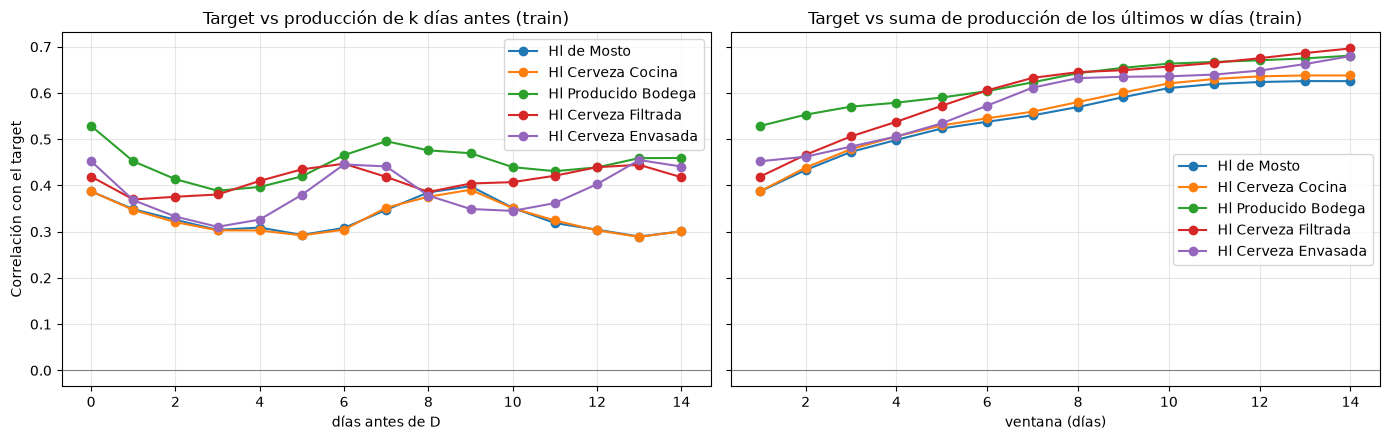

In [45]:
cols_prod = [
    "Consolidado Produccion | Hl de Mosto",
    "Consolidado Produccion | Hl Cerveza Cocina",
    "Consolidado Produccion | Hl Producido Bodega",
    "Consolidado Produccion | Hl Cerveza Filtrada",
    "Consolidado Produccion | Hl Cerveza Envasada",
]
faltan = [c for c in cols_prod if c not in df_train.columns]
print("No están en el df:", faltan) if faltan else None
cols_prod = [c for c in cols_prod if c in df_train.columns]

tr = df_train.sort_values("DIA")
rezagos = range(0, 15)
corto = {c: c.split(" | ", 1)[-1] for c in cols_prod}

# Correlación del target con la producción de k días antes de D
corr_rezago = pd.DataFrame({corto[c]: [tr["target"].corr(tr[c].shift(k)) for k in rezagos] for c in cols_prod},
                           index=pd.Index(rezagos, name="días antes de D"))

# Correlación del target con la suma de producción de los últimos w días (D-w+1 a D)
ventanas = range(1, 15)
corr_suma = pd.DataFrame({corto[c]: [tr["target"].corr(tr[c].rolling(w).sum()) for w in ventanas] for c in cols_prod},
                         index=pd.Index(ventanas, name="ventana (días)"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
corr_rezago.plot(ax=axes[0], marker="o", title="Target vs producción de k días antes (train)")
corr_suma.plot(ax=axes[1], marker="o", title="Target vs suma de producción de los últimos w días (train)")
axes[0].set_ylabel("Correlación con el target")
for ax in axes:
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

En el eje Y la correlación con frío, y en el eje X cuantos días tiene de diferencia con 0. 
Viendo el primer grafico, nos damos cuenta que el HL de cerveza envasada hace el pico a los 7 días, y despues vuelve a repetir el patrón. 

Hay un cambio semanal en la producción entonces. Bodega es la que más correlación tiene en el mismo día, y aumenta mucho la correlación para cerveza envasada y filtrada en el día 7. 

Con esto, conozco que hay una demora entre cada proceso y uso eso para crear las features: 
- Hago columnas que sean la producción hace 7 días para producido bodega y cerveza envasada. Filtrada ocurre un día antes, pero voy a mantenerlo en 7 por continuidad. 
- Para Cocina y mosto, parece que toma el valor máximo a los 9 días, así qeu las hago con esas. 

Aparte, le voy a hacer derivadas a los 4 sectores (a cocina y mosto no le hago uno por separado por que son iguales).

In [46]:
def rezago(datos, columna, nombre, k, previo=None, col_fecha="DIA"):
    """Valor de `columna` k días antes de D. Con `previo`, los primeros días toman la historia.
    Si no hay k días anteriores (inicio de la serie), usa el primer valor disponible."""
    resultado = serie_con_previo(datos, columna, previo, col_fecha).shift(k).bfill()
    datos = datos.copy()
    datos[nombre] = datos[col_fecha].map(resultado)
    return datos

In [47]:
# {columna: (sector, días de rezago)}
rezagos_prod = {
    "Consolidado Produccion | Hl de Mosto": ("mosto", 9),
    "Consolidado Produccion | Hl Cerveza Cocina": ("cocina", 9),
    "Consolidado Produccion | Hl Producido Bodega": ("bodega", 7),
    "Consolidado Produccion | Hl Cerveza Filtrada": ("filtrada", 7),
    "Consolidado Produccion | Hl Cerveza Envasada": ("envasada", 7),
}
# {columna: sector} para las derivadas (una por sector)
derivadas_prod = {
    "Consolidado Produccion | Hl Cerveza Cocina": "cocina",
    "Consolidado Produccion | Hl Producido Bodega": "bodega",
    "Consolidado Produccion | Hl Cerveza Filtrada": "filtrada",
    "Consolidado Produccion | Hl Cerveza Envasada": "envasada",
}


In [48]:
faltan = [c for c in {**rezagos_prod, **derivadas_prod, c_frio: None} if c not in df_train.columns]
assert not faltan, f"No están en el df: {faltan}"

nuevas = []
for col, (sector, k) in rezagos_prod.items():
    nombre = f"PROD_{sector}_lag{k}"
    df_train = rezago(df_train, col, nombre, k)
    df_val = rezago(df_val, col, nombre, k, previo=df_train)
    df_test = rezago(df_test, col, nombre, k, previo=pd.concat([df_train, df_val]))
    nuevas.append(nombre)

for col, sector in derivadas_prod.items():
    nombre = f"PROD_{sector}_dif"
    df_train = variacion(df_train, col, nombre)
    df_val = variacion(df_val, col, nombre, previo=df_train)
    df_test = variacion(df_test, col, nombre, previo=pd.concat([df_train, df_val]))
    nuevas.append(nombre)

# Frío del mismo día de la semana que D+1, una semana antes (D - 6)
df_train = rezago(df_train, c_frio, "FRIO_lag6", 6)
df_val = rezago(df_val, c_frio, "FRIO_lag6", 6, previo=df_train)
df_test = rezago(df_test, c_frio, "FRIO_lag6", 6, previo=pd.concat([df_train, df_val]))
nuevas.append("FRIO_lag6")

print(f"Columnas nuevas: {len(nuevas)}")
for nombre, d in [("Train", df_train), ("Validación", df_val), ("Test", df_test)]:
    print(f"{nombre:<11} {d.shape} | nulos nuevos: {d[nuevas].isna().sum().sum()}")
print(f"Corr con target (train): FRIO_lag6 {df_train['FRIO_lag6'].corr(df_train['target']):.3f} | "
      f"Frio de D {df_train[c_frio].corr(df_train['target']):.3f}")

Columnas nuevas: 10
Train       (849, 326) | nulos nuevos: 0
Validación  (182, 326) | nulos nuevos: 0
Test        (182, 326) | nulos nuevos: 0
Corr con target (train): FRIO_lag6 0.732 | Frio de D 0.843


### Ratios de Producción

Se sugieren ratios de producción, pero como no encuentro una buena relación base para armarlos a mano, lo que voy a hacer es armar una columna de ratio para cada parte de producción: (Zona_Producción / Frio). 

La idea es que te diga cuantos Hl de cada etapa pasan por cada Kw de frío, entonces al modelo le da una relación entre Kw y Hl. Ya existen relaciones parecidas en las columnas, pero las voy a dejar y en todo caso los selectores las sacan.

In [49]:
def agregar_combinaciones(datos, ratios=None, interacciones=None):
    """Agrega columnas calculadas con valores del mismo día (no ajusta nada con train, no necesita `previo`).
    ratios: {nombre: (numerador, denominador)} -> numerador / denominador (0 si el denominador es 0).
    interacciones: {nombre: (col_a, col_b)} -> col_a * col_b."""
    ratios, interacciones = ratios or {}, interacciones or {}
    nuevas = {}
    for nombre, (num, den) in ratios.items():
        nuevas[nombre] = (datos[num] / datos[den]).where(datos[den] != 0, 0)
    for nombre, (a, b) in interacciones.items():
        nuevas[nombre] = datos[a] * datos[b]
    datos = datos.drop(columns=list(nuevas), errors="ignore")   # si se vuelve a correr, no duplica
    return pd.concat([datos, pd.DataFrame(nuevas, index=datos.index)], axis=1)

In [50]:
# Hl de cada columna de producción por kW de frío del día (producción / frío: el frío nunca es 0)
cols_prod_ratio = [c for c in df_train.columns if c.startswith("Consolidado Produccion")]

def sector_de(col):
    """'Consolidado Produccion | Hl Producido Bodega' -> 'bodega'; 'Hl Cerveza L2' -> 'l2'."""
    nombre = re.sub(r"\b(Hl|Cerveza|Producido|de)\b", "", col.split(" | ", 1)[-1])
    return "_".join(nombre.lower().split())

ratios_prod = {f"RATIO_{sector_de(c)}_frio": (c, c_frio) for c in cols_prod_ratio}

df_train = agregar_combinaciones(df_train, ratios=ratios_prod)
df_val = agregar_combinaciones(df_val, ratios=ratios_prod)
df_test = agregar_combinaciones(df_test, ratios=ratios_prod)

corr = df_train[list(ratios_prod)].corrwith(df_train["target"]).round(3)
print(f"Columnas nuevas: {len(ratios_prod)} | shapes: train {df_train.shape}, val {df_val.shape}, test {df_test.shape}")
print("Corr con target (train):", corr.to_dict())

Columnas nuevas: 9 | shapes: train (849, 335), val (182, 335), test (182, 335)
Corr con target (train): {'RATIO_mosto_frio': -0.194, 'RATIO_cocina_frio': -0.158, 'RATIO_bodega_frio': -0.309, 'RATIO_filtrada_frio': -0.288, 'RATIO_envasada_frio': -0.28, 'RATIO_l2_frio': -0.155, 'RATIO_l3_frio': -0.181, 'RATIO_l4_frio': -0.237, 'RATIO_l5_frio': 0.002}


### Eficiencia en producción 

Ya lo habia comentado en los valores nulos, están las columnas de meta vinculadas a la producción del KPI. Mi plan es tomar la feature recomendada, eficiencia energética que es consumo Hl/meta. 

In [51]:
def agregar_eficiencias(datos, medias=None):
    """Crea efic_<X> = (X / Hl) / (Meta X) para cada meta que tiene su KPI.
    Solo en días con meta (no_hay_meta == 0); el resto lleva la media de train.
    Con medias=None (train) las calcula; si no, aplica las recibidas. Devuelve (datos, medias)."""
    # 'Meta EE Planta' y 'EE Planta / Hl' -> 'eeplanta' (sin hoja, sin 'Meta', sin '/Hl', sin espacios)
    clave = lambda c: re.sub(r"\s+", "", c.split(" | ", 1)[-1].lower().removeprefix("meta").split("/")[0])
    kpis = {clave(c): c for c in datos.columns if c.lower().replace(" ", "").endswith("/hl")}
    metas = [c for c in datos.columns if c.split(" | ", 1)[-1].strip().lower().startswith("meta")]

    calcular = medias is None
    medias = {} if calcular else medias
    nuevas = {}
    for meta in metas:
        kpi = kpis.get(clave(meta))
        if kpi is None:
            continue
        nombre = "efic_" + kpi.split(" | ", 1)[-1].split("/")[0].strip()
        efic = (datos[kpi] / datos[meta]).where(datos["no_hay_meta"].eq(0) & datos[meta].ne(0))
        if calcular:
            medias[nombre] = float(efic.mean())
        nuevas[nombre] = efic.fillna(medias[nombre])

    datos = datos.drop(columns=list(nuevas), errors="ignore")   # si se vuelve a correr, no duplica
    return pd.concat([datos, pd.DataFrame(nuevas, index=datos.index)], axis=1), medias

In [52]:
df_train, medias_efic = agregar_eficiencias(df_train)
df_val, _ = agregar_eficiencias(df_val, medias_efic)
df_test, _ = agregar_eficiencias(df_test, medias_efic)

registro_columnas["medias_train"] = {"eficiencias": medias_efic}
registrar_tratamiento(list(medias_efic), "media_train_si_no_hay_meta")
ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8")

n_metas = sum(c.split(" | ", 1)[-1].strip().lower().startswith("meta") for c in df_train.columns)
print(f"Eficiencias creadas: {len(medias_efic)} de {n_metas} metas")
print(f"Shapes: train {df_train.shape} | val {df_val.shape} | test {df_test.shape}")

media_train_si_no_hay_meta: 48 columnas registradas en tratamiento_columnas.json
Eficiencias creadas: 48 de 49 metas
Shapes: train (849, 383) | val (182, 383) | test (182, 383)


Imputo las metas que faltaban para el primer año de datos con la media, como habia mencionado en los valores nulos.

In [53]:
def imputar_metas(datos, medias=None):
    """Reemplaza el 1 provisorio de los días sin meta (no_hay_meta == 1) por la media de cada meta en los días con meta.
    Con medias=None (train) las calcula; si no, aplica las recibidas. Devuelve (datos, medias)."""
    datos = datos.copy()
    metas = [c for c in datos.columns if c.split(" | ", 1)[-1].strip().lower().startswith("meta")]
    con_meta = datos["no_hay_meta"].eq(0)
    if medias is None:
        medias = {m: float(datos.loc[con_meta, m].mean()) for m in metas}
    datos.loc[~con_meta, metas] = pd.DataFrame(medias, index=datos.index[~con_meta])
    return datos, medias


In [54]:
df_train, medias_metas = imputar_metas(df_train)
df_val, _ = imputar_metas(df_val, medias_metas)
df_test, _ = imputar_metas(df_test, medias_metas)

registro_columnas["medias_train"]["metas"] = medias_metas
ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8")

print(f"Metas imputadas: {len(medias_metas)} | días sin meta: train {df_train['no_hay_meta'].sum()}, "
      f"val {df_val['no_hay_meta'].sum()}, test {df_test['no_hay_meta'].sum()}")

Metas imputadas: 49 | días sin meta: train 427, val 0, test 0


### Guardado

Voy a necesitar que columnas y con que parámetros (para las funciones auxiliares) se trabajó para crear las features, lo guardo en el json:

In [55]:
# Pares meta-KPI con la misma regla que agregar_eficiencias
clave = lambda c: re.sub(r"\s+", "", c.split(" | ", 1)[-1].lower().removeprefix("meta").split("/")[0])
kpis = {clave(c): c for c in df_train.columns if c.lower().replace(" ", "").endswith("/hl")}
metas_df = [c for c in df_train.columns if c.split(" | ", 1)[-1].strip().lower().startswith("meta")]
pares_efic = {"efic_" + kpis[clave(m)].split(" | ", 1)[-1].split("/")[0].strip(): [m, kpis[clave(m)]]
              for m in metas_df if clave(m) in kpis}
assert set(pares_efic) == set(medias_efic), "Los pares no coinciden con las eficiencias creadas"

# En orden de aplicación: las variaciones de FRIO_media5 necesitan que exista FRIO_media5
registro_columnas["features"] = {
    "temperatura": {"csv": "data/external/temperatura_tecate.csv", "columnas": cols_temp},
    "medias_moviles": {"FRIO_media5": [c_frio, 5], "FRIO_media14": [c_frio, 14]},
    "variaciones": {"FRIO_media5_dif": "FRIO_media5",
                    **{f"PROD_{s}_dif": c for c, s in derivadas_prod.items()}},
    "rezagos": {**{f"PROD_{s}_lag{k}": [c, k] for c, (s, k) in rezagos_prod.items()},
                "FRIO_lag6": [c_frio, 6]},
    "ratios": {nombre: list(par) for nombre, par in ratios_prod.items()},
    "eficiencias": pares_efic,
}
ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8")
print({grupo: len(v) if isinstance(v, dict) else v for grupo, v in registro_columnas["features"].items()})

{'temperatura': 2, 'medias_moviles': 2, 'variaciones': 5, 'rezagos': 6, 'ratios': 9, 'eficiencias': 48}


## Selección de variables